# Wave Energy Assignment
**OE44170 – Offshore Renewable Technologies 2026 – Group 21**

Data: `data/WaveData_students11.xlsx` (Sheet1 = time series, Sheet2 = power matrix). Figures are saved in `output/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

OUT_DIR = "output"
DATA_FILE = "data/WaveData_students11.xlsx"
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})

RHO = 1025.0   # kg/m3
G = 9.81       # m/s2
STUDENT_IDS = [5578620, 6537197, 2723314]

---
# Task 1 – JONSWAP

$$U_a = 0.71\,U_{10}^{1.23}, \qquad \hat F = \frac{gF}{U_a^2}$$
$$H_{m0} = a\,\hat F^{0.5}\,\frac{U_a^2}{g}, \qquad T_p = b\,\hat F^{0.33}\,\frac{U_a}{g}, \qquad a = 0.0016,\ b = 0.2857$$
$$P_{reg} = \frac{\rho g^2 H_{m0}^2 T_e}{32\pi}, \qquad P_{irr} = \frac{\rho g^2 H_{m0}^2 T_e}{64\pi}, \qquad T_e = 0.9\,T_p$$

In [2]:
def jonswap(fetch, u10, a=0.0016, b=0.2857):
    ua = 0.71 * u10**1.23
    f_hat = G * fetch / ua**2
    hm0 = a * f_hat**0.5 * ua**2 / G
    tp = b * f_hat**0.33 * ua / G
    return ua, f_hat, hm0, tp


def p_regular(h, te):
    return RHO * G**2 * h**2 * te / (32 * np.pi)   # W/m


def p_irregular(h, te):
    return RHO * G**2 * h**2 * te / (64 * np.pi)   # W/m


# check with lecture example (F = 5 km, U10 = 20 m/s -> 1.02 m, 3.20 s)
_, _, h_ex, t_ex = jonswap(5000, 20)
print(f"Lecture example: Hm0 = {h_ex:.2f} m, Tp = {t_ex:.2f} s")

Lecture example: Hm0 = 1.02 m, Tp = 3.20 s


In [3]:
FETCH = float(sum(STUDENT_IDS))   # m
U10 = 30.0                        # m/s

Ua, F_hat, Hm0_1, Tp_1 = jonswap(FETCH, U10)
Te_1 = 0.9 * Tp_1
P_reg_1 = p_regular(Hm0_1, Te_1)
P_irr_1 = p_irregular(Hm0_1, Te_1)

print(f"F     = {FETCH:,.0f} m")
print(f"Ua    = {Ua:.2f} m/s")
print(f"F_hat = {F_hat:,.0f}")
print(f"Hm0   = {Hm0_1:.2f} m")
print(f"Tp    = {Tp_1:.2f} s   (Te = {Te_1:.2f} s)")
print(f"P_reg = {P_reg_1:.3e} W/m")
print(f"P_irr = {P_irr_1:.3e} W/m")

F     = 14,839,131 m
Ua    = 46.57 m/s
F_hat = 67,119
Hm0   = 91.64 m
Tp    = 53.11 s   (Te = 47.80 s)
P_reg = 3.939e+08 W/m
P_irr = 1.970e+08 W/m


The fetch (~14 800 km) is much longer than any real basin. JONSWAP keeps growing with $\hat F^{0.5}$, so the sea state is unrealistic; a fully developed sea at 30 m/s would be around 20 m.

---
# Task 2 – Statistics of $H_{m0}$, $T_p$, $P_{wave}$

$P_{wave} = \rho g^2 H_{m0}^2 T_e / (64\pi)$ per hour, with $T_e = 0.9\,T_p$.

In [4]:
ts = pd.read_excel(DATA_FILE, sheet_name="Sheet1")
ts.columns = ["Hm0", "Tp"]
ts = ts.dropna().reset_index(drop=True)
N = len(ts)
t_days = np.arange(N) / 24

ts["P"] = p_irregular(ts["Hm0"], 0.9 * ts["Tp"])   # W/m

stats = pd.DataFrame({"Hm0 [m]": ts["Hm0"], "Tp [s]": ts["Tp"], "Pwave [kW/m]": ts["P"] / 1e3})
stats = stats.agg(["mean", "std", "max", "min"]).T
stats.round(2)

,mean,std,max,min
Hm0 [m],1.90,0.92,6.31,0.45
Tp [s],10.83,2.84,19.19,3.14
Pwave [kW/m],24.36,31.44,306.63,0.54


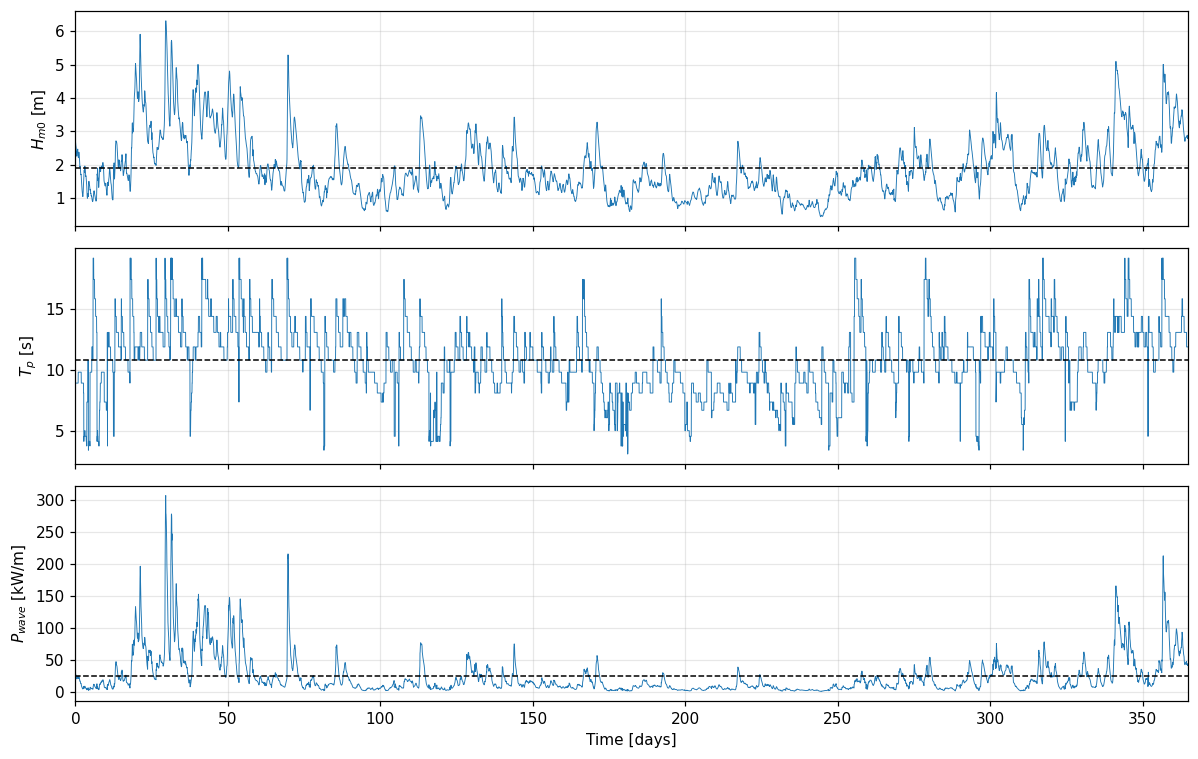

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, y, lab in zip(axes, [ts["Hm0"], ts["Tp"], ts["P"] / 1e3],
                      ["$H_{m0}$ [m]", "$T_p$ [s]", "$P_{wave}$ [kW/m]"]):
    ax.plot(t_days, y, lw=0.6)
    ax.axhline(y.mean(), color="k", ls="--", lw=1)
    ax.set_ylabel(lab)
axes[-1].set_xlabel("Time [days]")
axes[-1].set_xlim(0, t_days[-1])
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/wave_timeseries.png")
plt.show()

---
# Task 3 – Power production and capacity factor

Each hour is put in the nearest $(H_{m0}, T_p)$ bin of the power matrix.

$$\bar P = \sum_i\sum_j P(H_{m0}\cap T_p)_{ij}\,PM_{ij}, \qquad AEP = \bar P \cdot 8760, \qquad CF = \frac{AEP}{8760\,P_0}$$

In [6]:
pm_raw = pd.read_excel(DATA_FILE, sheet_name="Sheet2", header=None)
TP_BINS = pm_raw.iloc[1, 2:].astype(float).to_numpy()
HS_BINS = pm_raw.iloc[2:, 1].astype(float).to_numpy()
PM = pm_raw.iloc[2:, 2:].astype(float).to_numpy()   # kW
P_RATED = PM.max()
dH, dT = 0.5, 1.0

i_h = np.clip(np.rint(ts["Hm0"] / dH).astype(int), 0, len(HS_BINS) - 1)
i_t = np.clip(np.rint(ts["Tp"] / dT).astype(int), 0, len(TP_BINS) - 1)   # Tp > 18.5 s -> 18 s bin (0 kW)

OCC = np.zeros_like(PM)
np.add.at(OCC, (i_h, i_t), 1)
PROB = OCC / N
P_SS = PROB * PM            # kW, contribution per sea state
E_SS = OCC * PM / 1e3       # MWh per sea state

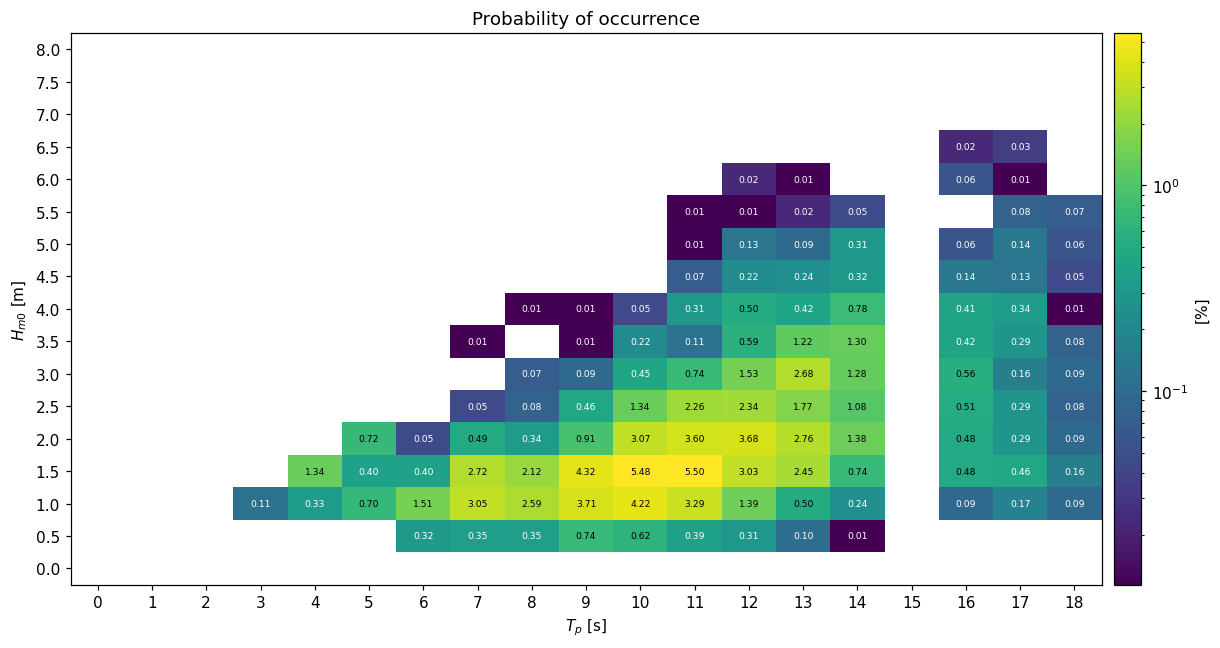

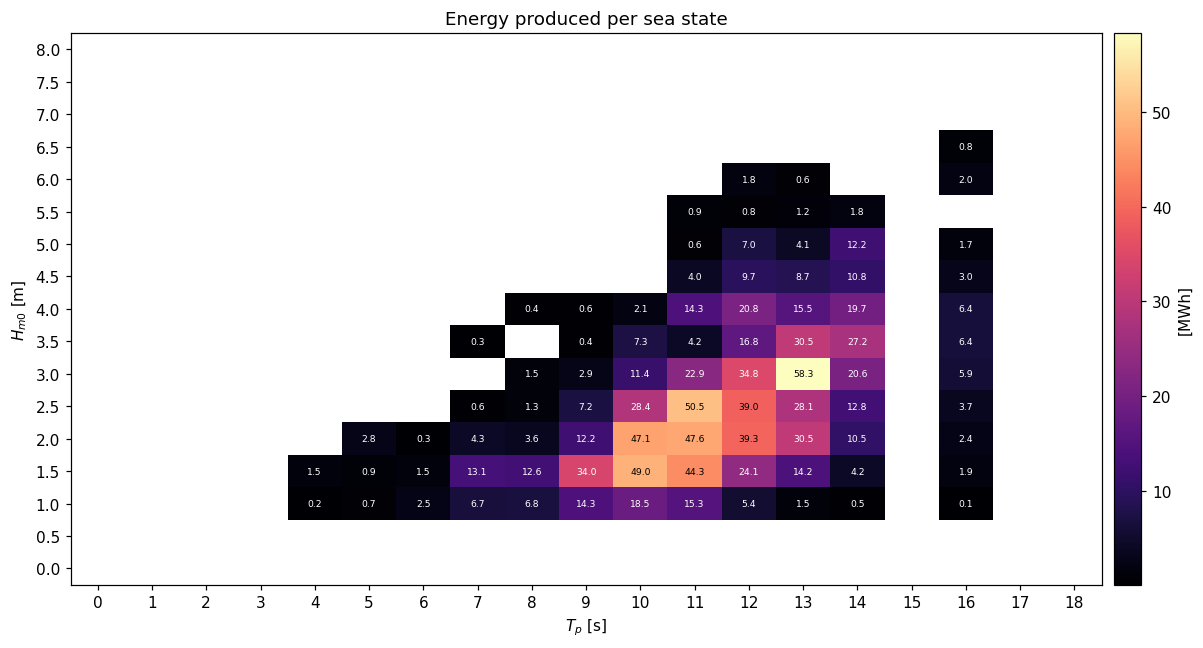

In [7]:
def heatmap(mat, title, label, fname, fmt, log=False, cmap="viridis"):
    fig, ax = plt.subplots(figsize=(12, 6))
    m = np.ma.masked_where(mat <= 0, mat)
    im = ax.pcolormesh(np.append(TP_BINS - dT / 2, TP_BINS[-1] + dT / 2),
                       np.append(HS_BINS - dH / 2, HS_BINS[-1] + dH / 2),
                       m, cmap=cmap, norm=LogNorm() if log else None)
    for i, h in enumerate(HS_BINS):
        for j, tp in enumerate(TP_BINS):
            if mat[i, j] > 0:
                ax.text(tp, h, fmt.format(mat[i, j]), ha="center", va="center", fontsize=6,
                        color="white" if im.norm(mat[i, j]) < 0.6 else "black")
    ax.set_xticks(TP_BINS)
    ax.set_yticks(HS_BINS)
    ax.set_xlabel("$T_p$ [s]")
    ax.set_ylabel("$H_{m0}$ [m]")
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, label=label, pad=0.01)
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/{fname}")
    plt.show()


heatmap(PROB * 100, "Probability of occurrence", "[%]", "occurrence_matrix.png", "{:.2f}", log=True)
heatmap(E_SS, "Energy produced per sea state", "[MWh]", "energy_per_sea_state.png", "{:.1f}", cmap="magma")

In [8]:
occ_df = pd.DataFrame(OCC.astype(int), index=HS_BINS, columns=TP_BINS.astype(int))
occ_df.loc[0.5:6.5, 3:18]

,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0.5,0,0,0,28,31,31,65,54,34,27,9,1,0,0,0,0
1.0,10,29,61,132,267,227,325,370,288,122,44,21,0,8,15,8
1.5,0,117,35,35,238,186,378,480,482,265,215,65,0,42,40,14
2.0,0,0,63,4,43,30,80,269,315,322,242,121,0,42,25,8
2.5,0,0,0,0,4,7,40,117,198,205,155,95,0,45,25,7
3.0,0,0,0,0,0,6,8,39,65,134,235,112,0,49,14,8
3.5,0,0,0,0,1,0,1,19,10,52,107,114,0,37,25,7
4.0,0,0,0,0,0,1,1,4,27,44,37,68,0,36,30,1
4.5,0,0,0,0,0,0,0,0,6,19,21,28,0,12,11,4
5.0,0,0,0,0,0,0,0,0,1,11,8,27,0,5,12,5


In [9]:
pss_df = pd.DataFrame(P_SS, index=HS_BINS, columns=TP_BINS.astype(int))
pss_df.loc[0.5:6.5, 3:18].round(2)

,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0.5,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.0
1.0,0.0,0.02,0.08,0.29,0.76,0.78,1.63,2.11,1.74,0.61,0.17,0.05,0.0,0.02,0.0,0.0
1.5,0.0,0.17,0.10,0.17,1.49,1.44,3.88,5.59,5.06,2.75,1.62,0.48,0.0,0.22,0.0,0.0
2.0,0.0,0.00,0.32,0.03,0.49,0.41,1.40,5.38,5.43,4.49,3.48,1.20,0.0,0.28,0.0,0.0
2.5,0.0,0.00,0.00,0.00,0.06,0.15,0.82,3.25,5.77,4.45,3.20,1.46,0.0,0.43,0.0,0.0
3.0,0.0,0.00,0.00,0.00,0.00,0.17,0.33,1.30,2.62,3.98,6.65,2.35,0.0,0.67,0.0,0.0
3.5,0.0,0.00,0.00,0.00,0.03,0.00,0.05,0.84,0.48,1.92,3.48,3.11,0.0,0.73,0.0,0.0
4.0,0.0,0.00,0.00,0.00,0.00,0.05,0.06,0.24,1.64,2.38,1.77,2.24,0.0,0.74,0.0,0.0
4.5,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.46,1.10,1.00,1.23,0.0,0.34,0.0,0.0
5.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.07,0.80,0.47,1.40,0.0,0.19,0.0,0.0


In [10]:
P_mean_wec = P_SS.sum()            # kW
AEP = P_mean_wec * 8760 / 1e3      # MWh
CF = AEP / (8760 * P_RATED / 1e3)

print(f"Mean power = {P_mean_wec:.1f} kW")
print(f"AEP        = {AEP:.0f} MWh/yr")
print(f"CF         = {CF * 100:.1f} %")

Mean power = 119.8 kW
AEP        = 1049 MWh/yr
CF         = 12.0 %


CF is low because most sea states are $H_{m0}$ = 1–2.5 m, $T_p$ = 9–13 s, where the matrix gives 50–250 kW. Rated power (1000 kW) needs $H_{m0} \geq 6$ m at $T_p$ = 8–12 s, which never occurs in the data.

---
# Task 4 – Heaving cylinder

$$|\zeta_3| = \frac{F_e\,\zeta_a}{\sqrt{\left(c_{33} - \omega^2(m + a_{33})\right)^2 + \omega^2\left(b_{33} + B_v + B_{PTO}\right)^2}}, \qquad \bar P = \tfrac12\,\omega^2 B_{PTO}\,|\zeta_3|^2$$

$\zeta_a = \overline{H_{m0}}/2$ from Task 2. Viscous damping is taken as 10 % of critical damping: $B_v = 0.1 \cdot 2\sqrt{(m + a_{33})\,c_{33}}$.

In [11]:
MASS = 6537197.0       # kg
B_PTO = 300_000.0      # Ns/m
VISC_RATIO = 0.10
ZETA_A = ts["Hm0"].mean() / 2

T = np.arange(4, 21)
Fe = np.array([92835, 191111, 287473, 370708, 440116, 493379, 537292, 571441, 599482,
               622822, 640732, 656066, 657556, 669490, 670931, 690200, 705314])       # N/m
b33 = np.array([16795, 36888, 48769, 51178, 47882, 42586, 36679, 31353, 26653,
                22505, 19341, 16556, 16285, 14186, 13931, 10561, 8016])               # Ns/m
a33 = np.array([210452, 207322, 215654, 229379, 243591, 255355, 265617, 273239, 278536,
                283906, 286085, 289244, 289586, 290272, 290446, 292754, 294449])      # kg
c33 = 770476.0                                                                        # N/m

w = 2 * np.pi / T
B_v = VISC_RATIO * 2 * np.sqrt((MASS + a33) * c33)
z_amp = Fe * ZETA_A / np.sqrt((c33 - w**2 * (MASS + a33))**2 + (w * (b33 + B_v + B_PTO))**2)
P_mean = 0.5 * w**2 * B_PTO * z_amp**2

res = pd.DataFrame({"T [s]": T, "B_v [Ns/m]": B_v.round(0), "|z3| [m]": z_amp.round(3),
                    "P [W]": P_mean.round(0)})
print(f"zeta_a = {ZETA_A:.3f} m")
res

zeta_a = 0.950 m


,T [s],B_v [Ns/m],|z3| [m],P [W]
0,4,456022.0,0.006,11.0
1,5,455916.0,0.018,79.0
2,6,456198.0,0.041,274.0
3,7,456661.0,0.074,668.0
4,8,457140.0,0.120,1342.0
5,9,457537.0,0.180,2373.0
6,10,457882.0,0.258,3936.0
7,11,458139.0,0.357,6239.0
8,12,458317.0,0.486,9696.0
9,13,458497.0,0.653,14956.0


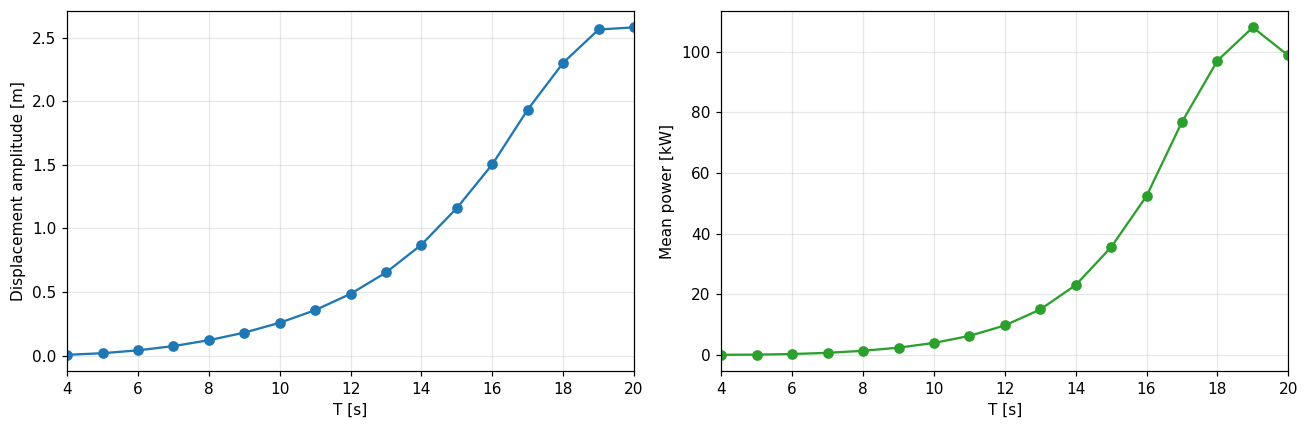

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(T, z_amp, "o-")
axes[0].set_ylabel("Displacement amplitude [m]")
axes[1].plot(T, P_mean / 1e3, "o-", color="tab:green")
axes[1].set_ylabel("Mean power [kW]")
for ax in axes:
    ax.set_xlabel("T [s]")
    ax.set_xlim(4, 20)
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/wec_heave_response.png")
plt.show()

Resonance is near $T_n = 2\pi\sqrt{(m + a_{33})/c_{33}} \approx 19$ s. The mass is very large for a cylinder with $A_w \approx 77$ m² ($c_{33} = \rho g A_w$), so the resonance sits far above the typical $T_p$ of the site (~11 s).